In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

In [2]:
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

classes = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

In [3]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Data preprocessing and augmentation
train_transform = transforms.Compose(
    [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)
test_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_dataset = torchvision.datasets.CIFAR10(
    root="./", train=True, download=False, transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./", train=False, download=False, transform=test_transform
)

train_loader = DataLoader(
    train_dataset, shuffle=True, batch_size=BATCH_SIZE, num_workers=2
)

test_loader = DataLoader(
    test_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=2
)

In [4]:
class CNNClassifer(nn.Module):
    def __init__(self):
        super().__init__()

        def block(n_in, n_out):
            return [
                nn.Conv2d(n_in, n_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(n_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2)
            ]

        self.features = nn.Sequential(*block(3, 64), *block(64, 128), *block(128, 256))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [5]:
model = CNNClassifer().to(device)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LEARNING_RATE, steps_per_epoch=len(train_loader), epochs=EPOCHS)
loss_fn = nn.CrossEntropyLoss()

epoch_losses = []
epoch_accuracies = []

# Training loop
for epoch in range(EPOCHS):
    model.train()

    epoch_total_loss = 0.0
    epoch_total = 0
    epoch_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(images)
        loss = loss_fn(logits, labels)

        # Backpropagation
        loss.backward()
        optimizer.step()
        scheduler.step()

        predictions = logits.argmax(axis=1)

        epoch_total_loss += loss.item() * images.size(0)
        epoch_total += len(labels)
        epoch_correct += (labels == predictions).sum().item()

    epoch_loss = epoch_total_loss / epoch_total
    epoch_accuracy = 100 * epoch_correct / epoch_total

    epoch_losses.append(epoch_loss)
    epoch_accuracies.append(epoch_accuracy)

    print(f"Epoch: {epoch+1}, Loss: {epoch_loss}, Accuracy: {epoch_accuracy}")

Epoch: 1, Loss: 1.9441484088134766, Accuracy: 28.104
Epoch: 2, Loss: 1.6010540113067626, Accuracy: 41.184
Epoch: 3, Loss: 1.4120325326538086, Accuracy: 48.916
Epoch: 4, Loss: 1.299565478515625, Accuracy: 53.124
Epoch: 5, Loss: 1.2286897817611695, Accuracy: 56.328
Epoch: 6, Loss: 1.1561920586776733, Accuracy: 58.826
Epoch: 7, Loss: 1.0939576280975343, Accuracy: 61.056
Epoch: 8, Loss: 1.0416253702545166, Accuracy: 62.996
Epoch: 9, Loss: 0.9932305853271485, Accuracy: 64.784
Epoch: 10, Loss: 0.9522157058334351, Accuracy: 66.362
Epoch: 11, Loss: 0.909793397064209, Accuracy: 68.126
Epoch: 12, Loss: 0.8711645799064637, Accuracy: 69.658
Epoch: 13, Loss: 0.8291372661590576, Accuracy: 71.138
Epoch: 14, Loss: 0.7955375232315064, Accuracy: 72.432
Epoch: 15, Loss: 0.7661502661132813, Accuracy: 73.556
Epoch: 16, Loss: 0.733409891242981, Accuracy: 74.67
Epoch: 17, Loss: 0.7076996144485473, Accuracy: 75.812
Epoch: 18, Loss: 0.6867150758552552, Accuracy: 76.494
Epoch: 19, Loss: 0.675016997680664, Accur

In [6]:
# Evaulation on test data
model.eval()

total = 0
total_correct = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(axis=1)

        total += len(labels)
        total_correct += (labels == predictions).sum().item()

accuracy = 100 * total_correct / total
print("Test Accuracy:", accuracy)

Test Accuracy: 78.41


In [7]:
torch.save(model.state_dict(), "model_state.pth")
print("Model saved")

Model saved


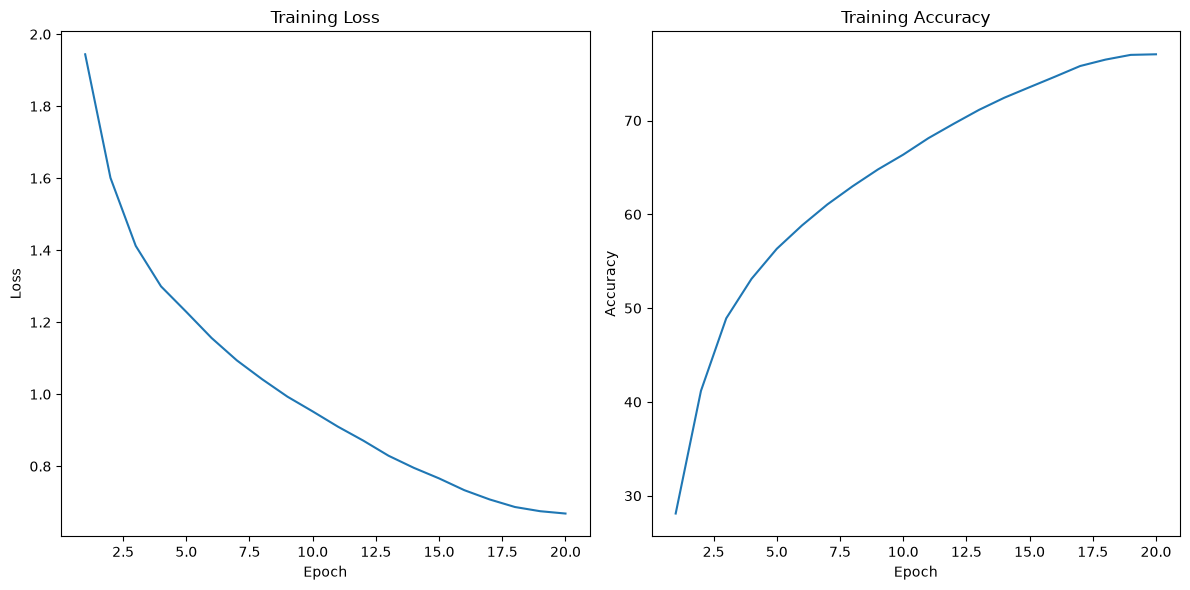

In [8]:
# Plot training loss and accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].plot(range(1, EPOCHS + 1), epoch_losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")

axes[1].plot(range(1, EPOCHS + 1), epoch_accuracies)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training Accuracy")

plt.tight_layout()
plt.show()

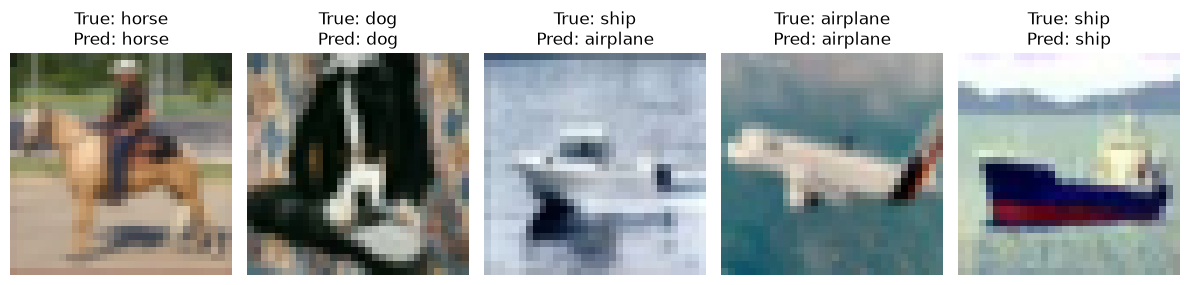

In [9]:
# Display sample predictions
mean_view = torch.tensor(mean).view(3, 1, 1)
std_view = torch.tensor(std).view(3, 1, 1)

fig, axes = plt.subplots(1, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i] * std_view + mean_view
    image = image.clamp(0, 1).permute(1, 2, 0)

    true_label = classes[labels[i].item()]
    pred_label = classes[predictions[i].item()]

    ax.imshow(image.numpy())
    ax.set_title(
        f"True: {true_label}\nPred: {pred_label}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()